# Proyek UTS Deep Learning - Deteksi Ekspresi Wajah
## Eksplorasi, Pemeriksaan Kualitas, dan Persiapan Dataset FER-2013

**Mata kuliah:** Deep Learning  
**Tahap:** UTS   
**Peran notebook:** Data Engineer (Anggota 2)

### Identitas kelompok
| No. | Nama | NIM |
|---:|---|---|
| 1 | Tulus Andriansah | 2330105030002 |
| 2 | Meisya Pradana Mentari | 2330105030020 |
| 3 | Alvin Nugraha Tangkawata |2330305030085 |
| 4 | Arbiyannoor Ilham Sanusie | 223020503097 |
| 5 | Christian Iuliano | 203010503003 |

### Tujuan notebook
Notebook ini mendokumentasikan proses kerja Data Engineer: memuat dataset dari file ZIP, memeriksa struktur folder, menghitung distribusi kelas, memvisualisasikan contoh gambar, memeriksa file gambar yang rusak, dan menyusun ringkasan awal untuk laporan UTS.

**Struktur dataset yang diharapkan:** folder `train` dan `test`, masing-masing berisi subfolder kelas ekspresi seperti `angry`, `disgust`, `fear`, `happy`, `neutral`, `sad`, dan `surprise`.



## Informasi sumber dataset dan lisensi

- **Nama dataset:** FER-2013.
- **URL sumber unduhan:** `https://www.kaggle.com/datasets/msambare/fer2013?resource=download`
- **Pemilik/pengunggah dataset:** `Manas Sambare`
- **Lisensi:** `https://opendatacommons.org/licenses/dbcl/1-0/`
- **Tanggal pengunduhan:** `23 Oktober 2026`


## Tahap 1 - Memuat dataset dari laptop

**Tujuan:** mengunggah ZIP dataset langsung ke sesi Google Colab.

In [1]:
from google.colab import files

uploaded_files = files.upload()

if not uploaded_files:
    raise RuntimeError("Tidak ada file yang diunggah. Jalankan ulang cell dan pilih file ZIP dataset.")

zip_candidates = [name for name in uploaded_files if name.lower().endswith(".zip")]
if not zip_candidates:
    raise ValueError("File yang diunggah bukan ZIP. Silakan unggah file .zip yang berisi folder train dan test.")

ZIP_NAME = zip_candidates[0]
ZIP_PATH = f"/content/{ZIP_NAME}"

print(f"File diterima: {ZIP_NAME}")
print(f"Ukuran file: {len(uploaded_files[ZIP_NAME]):,} byte")

Saving Dataset.zip to Dataset.zip
File diterima: Dataset.zip
Ukuran file: 63,252,113 byte


## Tahap 2 - Mengekstrak dataset

**Proses:** membuka file ZIP ke direktori sementara Colab (`/content/Dataset_ekstrak`).

**Mengapa dilakukan:** agar file gambar dapat dibaca dan dianalisis oleh Python. Cell ini juga memeriksa apakah arsip ZIP dapat dibuka sebelum diekstrak.

In [2]:
import zipfile
from pathlib import Path

EXTRACT_ROOT = Path("/content/Dataset_ekstrak")
EXTRACT_ROOT.mkdir(parents=True, exist_ok=True)

if not zipfile.is_zipfile(ZIP_PATH):
    raise ValueError("Arsip tidak terbaca sebagai ZIP yang valid.")

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_ROOT)

print("Ekstraksi selesai.")
print("Isi direktori hasil ekstraksi:")
for item in sorted(EXTRACT_ROOT.iterdir()):
    print(("📁 " if item.is_dir() else "📄 ") + item.name)

Ekstraksi selesai.
Isi direktori hasil ekstraksi:
📁 test
📁 train


## Tahap 3 - Menemukan dan memeriksa struktur train/test

**Proses:** mencari folder train dan test, termasuk jika keduanya berada satu tingkat di dalam folder lain.

**Tujuan:** memastikan notebook menunjuk ke lokasi dataset yang benar sebelum menghitung dan memeriksa gambar.


In [3]:
def find_split_dir(root: Path, split_name: str):
    matches = [p for p in root.rglob("*")
               if p.is_dir() and p.name.lower() == split_name.lower()]
    return matches[0] if matches else None

TRAIN_DIR = find_split_dir(EXTRACT_ROOT, "train")
TEST_DIR = find_split_dir(EXTRACT_ROOT, "test")

if TRAIN_DIR is None or TEST_DIR is None:
    raise FileNotFoundError(
        "Folder train/test tidak ditemukan. Periksa apakah ZIP berisi kedua folder tersebut."
    )

print("Folder train:", TRAIN_DIR)
print("Folder test :", TEST_DIR)

for split_name, split_dir in [("TRAIN", TRAIN_DIR), ("TEST", TEST_DIR)]:
    print(f"\nIsi tingkat pertama folder {split_name}:")
    for item in sorted(split_dir.iterdir())[:30]:
        print(("📁 " if item.is_dir() else "📄 ") + item.name)

Folder train: /content/Dataset_ekstrak/train
Folder test : /content/Dataset_ekstrak/test

Isi tingkat pertama folder TRAIN:
📁 angry
📁 disgust
📁 fear
📁 happy
📁 neutral
📁 sad
📁 surprise

Isi tingkat pertama folder TEST:
📁 angry
📁 disgust
📁 fear
📁 happy
📁 neutral
📁 sad
📁 surprise


## Tahap 4 - Menghitung jumlah gambar pada setiap kelas

**Proses:** menghitung file dengan ekstensi gambar umum di dalam subfolder kelas.

**Tujuan:** memeriksa jumlah sampel per kelas dan membandingkan train dengan test. Hasil perhitungan ini menjadi bukti eksplorasi dataset untuk bagian *Dataset & Preprocessing* pada laporan.

**Interpretasi awal:** jika jumlah antarkelas berbeda jauh, dataset mengalami ketidakseimbangan kelas (*class imbalance*). Hal ini perlu dipertimbangkan saat evaluasi model; jangan langsung menghapus atau menggandakan gambar hanya untuk menyamakan jumlah kelas.


In [4]:
from collections import Counter
import pandas as pd

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

def get_class_counts(split_dir: Path):
    counts = {}
    class_dirs = sorted([p for p in split_dir.iterdir() if p.is_dir()])
    for class_dir in class_dirs:
        counts[class_dir.name] = sum(
            1 for p in class_dir.rglob("*")
            if p.is_file() and p.suffix.lower() in IMAGE_EXTS
        )
    return counts

train_counts = get_class_counts(TRAIN_DIR)
test_counts = get_class_counts(TEST_DIR)

all_classes = sorted(set(train_counts) | set(test_counts))
distribution = pd.DataFrame({
    "Kelas": all_classes,
    "Train": [train_counts.get(c, 0) for c in all_classes],
    "Test": [test_counts.get(c, 0) for c in all_classes],
})
distribution["Total"] = distribution["Train"] + distribution["Test"]

display(distribution)
print(f"Total gambar train: {distribution['Train'].sum():,}")
print(f"Total gambar test : {distribution['Test'].sum():,}")
print(f"Total gambar      : {distribution['Total'].sum():,}")
print(f"Jumlah kelas      : {len(all_classes)}")

,Kelas,Train,Test,Total
0,angry,3995,958,4953
1,disgust,436,111,547
2,fear,4097,1024,5121
3,happy,7215,1774,8989
4,neutral,4965,1233,6198
5,sad,4830,1247,6077
6,surprise,3171,831,4002


Total gambar train: 28,709
Total gambar test : 7,178
Total gambar      : 35,887
Jumlah kelas      : 7


## Tahap 5 - Visualisasi distribusi kelas

**Proses:** membuat grafik batang untuk distribusi kelas pada train dan test secara terpisah.

**Tujuan:** melihat ketidakseimbangan kelas dengan cepat. Grafik ini dapat disimpan atau dirujuk ketika menulis pembahasan dataset di laporan.

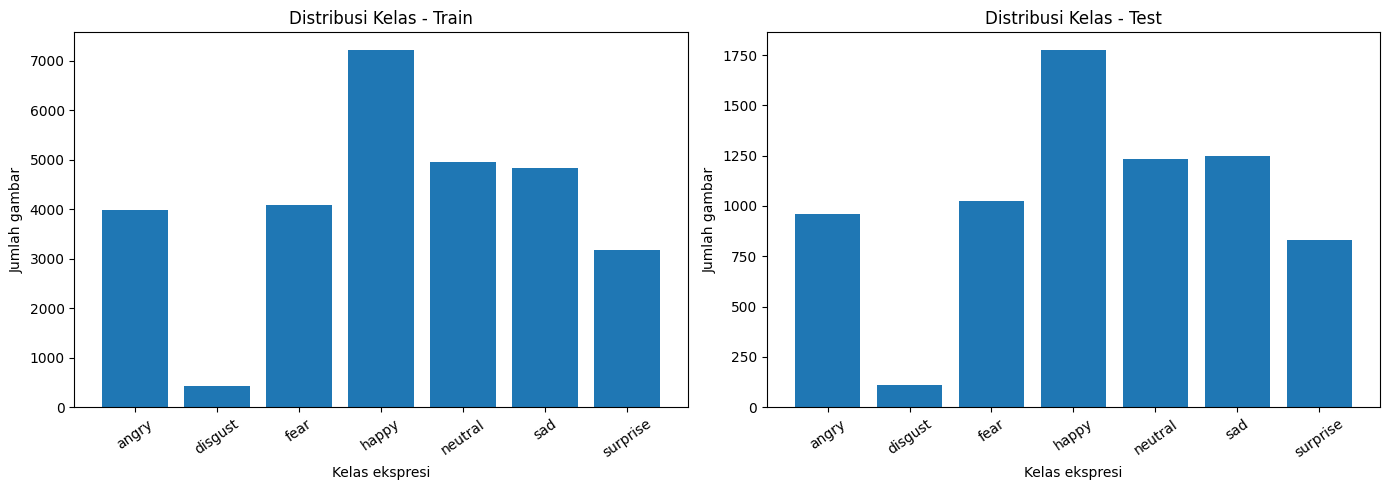

Kelas train terbanyak : happy (7,215 gambar)
Kelas train tersedikit: disgust (436 gambar)


In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(train_counts.keys(), train_counts.values())
axes[0].set_title("Distribusi Kelas - Train")
axes[0].set_xlabel("Kelas ekspresi")
axes[0].set_ylabel("Jumlah gambar")
axes[0].tick_params(axis="x", rotation=35)

axes[1].bar(test_counts.keys(), test_counts.values())
axes[1].set_title("Distribusi Kelas - Test")
axes[1].set_xlabel("Kelas ekspresi")
axes[1].set_ylabel("Jumlah gambar")
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

if train_counts:
    largest_class = max(train_counts, key=train_counts.get)
    smallest_class = min(train_counts, key=train_counts.get)
    print(f"Kelas train terbanyak : {largest_class} ({train_counts[largest_class]:,} gambar)")
    print(f"Kelas train tersedikit: {smallest_class} ({train_counts[smallest_class]:,} gambar)")

## Tahap 6 - Menampilkan contoh gambar dari setiap kelas

**Proses:** mengambil satu gambar acak dari setiap kelas pada data train dan menampilkannya bersama nama kelas.

**Tujuan:** pemeriksaan visual awal untuk memastikan file dapat dibaca dan memberi gambaran tentang isi data. Tampilan ini bukan evaluasi model dan tidak membuktikan bahwa semua label sudah benar.

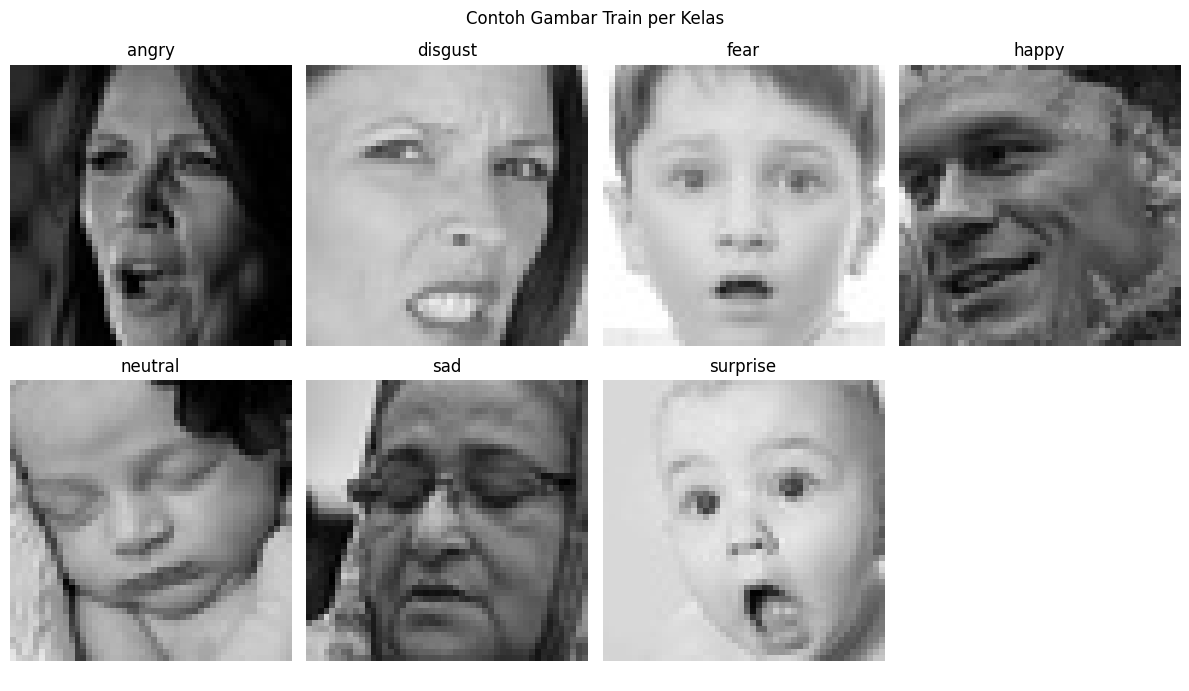

In [6]:
from PIL import Image
import random

random.seed(42)  # agar contoh yang dipilih dapat direproduksi

available_classes = [c for c in sorted(train_counts) if train_counts[c] > 0]
if not available_classes:
    print("Tidak ditemukan gambar di subfolder kelas. Periksa struktur dataset.")
else:
    ncols = 4
    nrows = (len(available_classes) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.5 * nrows))
    axes = list(axes.flatten()) if hasattr(axes, "flatten") else [axes]

    for ax in axes:
        ax.axis("off")

    for ax, label in zip(axes, available_classes):
        class_dir = TRAIN_DIR / label
        candidates = [p for p in class_dir.rglob("*")
                      if p.is_file() and p.suffix.lower() in IMAGE_EXTS]
        image_path = random.choice(candidates)
        with Image.open(image_path) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(label)
        ax.axis("off")

    plt.suptitle("Contoh Gambar Train per Kelas")
    plt.tight_layout()
    plt.show()

## Tahap 7 - Pemeriksaan karakteristik gambar

**Proses:** memeriksa dimensi, mode warna, dan format gambar dari sampel data train dan test.

**Tujuan:** mengetahui apakah ukuran dan representasi gambar konsisten. Informasi ini membantu anggota yang membangun MLP dan CNN menentukan preprocessing serta bentuk input yang sesuai.

**Catatan:** cell ini memeriksa seluruh file gambar dan dapat memerlukan waktu jika dataset besar. Pemeriksaan ini tidak mengubah file asli.

In [7]:
from PIL import Image
import pandas as pd
from collections import Counter

image_info = []
mode_counts = Counter()
format_counts = Counter()
dimension_counts = Counter()
read_errors = []

for split_name, split_dir in [("train", TRAIN_DIR), ("test", TEST_DIR)]:
    for class_dir in sorted(split_dir.iterdir()):
        if not class_dir.is_dir():
            continue
        for path in class_dir.rglob("*"):
            if not path.is_file() or path.suffix.lower() not in IMAGE_EXTS:
                continue
            try:
                with Image.open(path) as img:
                    width, height = img.size
                    mode = img.mode
                    fmt = img.format or path.suffix.lower()
                image_info.append({
                    "split": split_name,
                    "kelas": class_dir.name,
                    "lebar": width,
                    "tinggi": height,
                    "mode_warna": mode,
                    "format": fmt
                })
                mode_counts[mode] += 1
                format_counts[fmt] += 1
                dimension_counts[(width, height)] += 1
            except Exception as exc:
                read_errors.append((str(path), str(exc)))

df_images = pd.DataFrame(image_info)

print("Jumlah gambar yang berhasil dibaca:", len(df_images))
print("\nDistribusi mode warna:")
display(pd.DataFrame(mode_counts.items(), columns=["Mode warna", "Jumlah"]))
print("\nDistribusi format:")
display(pd.DataFrame(format_counts.items(), columns=["Format", "Jumlah"]))
print("\nDimensi gambar terbanyak:")
display(pd.DataFrame(
    [(f"{w}x{h}", n) for (w, h), n in dimension_counts.most_common()],
    columns=["Dimensi (lebar x tinggi)", "Jumlah"]
).head(20))

if not df_images.empty:
    print("\nRingkasan dimensi:")
    print("Lebar unik:", sorted(df_images["lebar"].unique()))
    print("Tinggi unik:", sorted(df_images["tinggi"].unique()))

print("\nFile yang gagal dibaca pada pemeriksaan ini:", len(read_errors))

Jumlah gambar yang berhasil dibaca: 35887

Distribusi mode warna:


,Mode warna,Jumlah
0,L,35887



Distribusi format:


,Format,Jumlah
0,JPEG,35887



Dimensi gambar terbanyak:


,Dimensi (lebar x tinggi),Jumlah
0,48x48,35887



Ringkasan dimensi:
Lebar unik: [np.int64(48)]
Tinggi unik: [np.int64(48)]

File yang gagal dibaca pada pemeriksaan ini: 0


## Tahap 8 - Memeriksa file gambar yang rusak/tidak terbaca

**Proses:** mencoba membuka dan memvalidasi setiap file gambar pada train dan test.

**Tujuan:** menemukan file yang mungkin tidak dapat dibaca oleh library gambar. Pemeriksaan ini tidak menghapus atau mengubah file; file bermasalah hanya dicatat agar dapat ditinjau lebih lanjut.

In [8]:
from PIL import Image

bad_images = []
checked_images = 0

for split_name, split_dir in [("train", TRAIN_DIR), ("test", TEST_DIR)]:
    for path in split_dir.rglob("*"):
        if path.is_file() and path.suffix.lower() in IMAGE_EXTS:
            checked_images += 1
            try:
                with Image.open(path) as img:
                    img.verify()
            except Exception as exc:
                bad_images.append((split_name, str(path), str(exc)))

print(f"Jumlah file gambar diperiksa: {checked_images:,}")
print(f"Jumlah file tidak terbaca    : {len(bad_images):,}")

if bad_images:
    print("\nContoh file bermasalah (maksimal 10):")
    for split_name, path, error in bad_images[:10]:
        print(f"[{split_name}] {path} - {error}")
else:
    print("Semua file gambar yang diperiksa dapat divalidasi.")

Jumlah file gambar diperiksa: 35,887
Jumlah file tidak terbaca    : 0
Semua file gambar yang diperiksa dapat divalidasi.


## Tahap 9 - Pemeriksaan duplikasi identik lintas train dan test

**Proses:** menghitung hash SHA-256 dari representasi piksel RGB setiap gambar, kemudian memeriksa apakah representasi yang identik muncul pada kedua subset.

**Tujuan:** mengidentifikasi potensi kebocoran data akibat gambar identik berada di train dan test.

**Batasan:** pemeriksaan ini hanya menemukan gambar yang piksel RGB-nya identik setelah konversi. Gambar yang sama tetapi diubah ukuran, dipotong, atau diedit mungkin tidak terdeteksi. Jika ada temuan, tinjau terlebih dahulu, jangan otomatis menghapus file.

In [9]:
import hashlib
from collections import defaultdict
from PIL import Image

hash_locations = defaultdict(list)

for split_name, split_dir in [("train", TRAIN_DIR), ("test", TEST_DIR)]:
    for path in split_dir.rglob("*"):
        if not path.is_file() or path.suffix.lower() not in IMAGE_EXTS:
            continue
        try:
            with Image.open(path) as img:
                img.load()
                pixel_bytes = img.convert("RGB").tobytes()
                digest = hashlib.sha256(pixel_bytes).hexdigest()
            hash_locations[digest].append((split_name, str(path)))
        except Exception:
            # File gagal dibaca sudah diperiksa pada tahap pemeriksaan kualitas.
            continue

cross_split_duplicates = []
for digest, locations in hash_locations.items():
    split_names = {split for split, _ in locations}
    if len(split_names) > 1:
        cross_split_duplicates.append((digest, locations))

print("Jumlah hash identik yang muncul lintas train/test:",
      len(cross_split_duplicates))

if cross_split_duplicates:
    print("\nContoh temuan (maksimal 10):")
    for digest, locations in cross_split_duplicates[:10]:
        print("Hash:", digest[:16] + "...")
        for split_name, path in locations:
            print(f"  [{split_name}] {path}")
else:
    print("Tidak ditemukan gambar dengan piksel identik lintas train dan test.")

Jumlah hash identik yang muncul lintas train/test: 531

Contoh temuan (maksimal 10):
Hash: e409c224621104d1...
  [train] /content/Dataset_ekstrak/train/happy/Training_22116956.jpg
  [test] /content/Dataset_ekstrak/test/happy/PublicTest_13648674.jpg
Hash: f3af779050c8e573...
  [train] /content/Dataset_ekstrak/train/happy/Training_63816018.jpg
  [train] /content/Dataset_ekstrak/train/happy/Training_93929505.jpg
  [test] /content/Dataset_ekstrak/test/happy/PublicTest_80609952.jpg
Hash: ebc934ffe7c472b2...
  [train] /content/Dataset_ekstrak/train/happy/Training_94370843.jpg
  [test] /content/Dataset_ekstrak/test/happy/PublicTest_18496904.jpg
Hash: 12a9a366e74b77c2...
  [train] /content/Dataset_ekstrak/train/happy/Training_15805577.jpg
  [train] /content/Dataset_ekstrak/train/happy/Training_81913976.jpg
  [test] /content/Dataset_ekstrak/test/happy/PublicTest_2337656.jpg
Hash: b212974f0cbc7b83...
  [train] /content/Dataset_ekstrak/train/happy/Training_25269203.jpg
  [test] /content/Dataset_e

## Tahap 10 - Ringkasan Temuan untuk Laporan UTS

**Proses:** Merangkum jumlah sampel, distribusi kelas, dan hasil pemeriksaan file.

**Catatan:**
- Sumber dataset dan lisensi harus diisi berdasarkan halaman unduhan yang benar-benar digunakan oleh kelompok. Jangan menganggap lisensi telah terverifikasi hanya berdasarkan nama dataset.

**Catatan Teknis:**
- **Pemeriksaan duplikasi:** Pemeriksaan dilakukan dengan membandingkan hash SHA-256 dari representasi piksel gambar yang telah dikonversi ke RGB. Metode ini membantu menemukan gambar dengan isi piksel identik, tetapi belum tentu mendeteksi gambar yang sama apabila ukuran, kualitas, atau isi pikselnya berbeda akibat pemrosesan.

- **Karakteristik gambar:** Dimensi, mode warna, dan format gambar perlu dicatat sebagai bagian dari pemeriksaan kualitas dataset.

- **File rusak:** Jumlah file gambar yang tidak dapat dibaca perlu dicatat berdasarkan hasil pemeriksaan.

- **Ketidakseimbangan kelas:** Jumlah gambar pada setiap kelas ekspresi perlu diperhatikan karena perbedaan jumlah sampel dapat memengaruhi proses pelatihan dan evaluasi model.

- **Pembagian data:** Data validation perlu disiapkan dari data train sebelum pelatihan model. Data test harus tetap terpisah dan tidak digunakan untuk memilih model atau mengatur hyperparameter.

In [10]:
total_train = sum(train_counts.values())
total_test = sum(test_counts.values())
total_all = total_train + total_test

print("RINGKASAN DATASET")
print("=" * 40)
print(f"Lokasi train                 : {TRAIN_DIR}")
print(f"Lokasi test                  : {TEST_DIR}")
print(f"Jumlah kelas train terdeteksi: {len(train_counts)}")
print(f"Jumlah kelas test terdeteksi : {len(test_counts)}")
print(f"Jumlah gambar train          : {total_train:,}")
print(f"Jumlah gambar test           : {total_test:,}")
print(f"Total gambar                 : {total_all:,}")
print(f"File gambar tidak terbaca    : {len(bad_images):,}")

if train_counts:
    print(f"Kelas train terbanyak        : {max(train_counts, key=train_counts.get)}")
    print(f"Kelas train tersedikit       : {min(train_counts, key=train_counts.get)}")

print("\nLengkapi catatan berikut secara manual untuk laporan:")
print("- Nama dataset dan URL sumber:")
print("- Lisensi sesuai halaman sumber:")
print("- Format gambar dan ukuran gambar:")
print("- Metode pembagian train/validation/test yang disepakati:")

RINGKASAN DATASET
Lokasi train                 : /content/Dataset_ekstrak/train
Lokasi test                  : /content/Dataset_ekstrak/test
Jumlah kelas train terdeteksi: 7
Jumlah kelas test terdeteksi : 7
Jumlah gambar train          : 28,709
Jumlah gambar test           : 7,178
Total gambar                 : 35,887
File gambar tidak terbaca    : 0
Kelas train terbanyak        : happy
Kelas train tersedikit       : disgust

Lengkapi catatan berikut secara manual untuk laporan:
- Nama dataset dan URL sumber:
- Lisensi sesuai halaman sumber:
- Format gambar dan ukuran gambar:
- Metode pembagian train/validation/test yang disepakati:


## Tahap 11 - Keputusan sebelum preprocessing lanjutan

Sebelum melakukan transformasi gambar atau menyiapkan validation set, diskusikan hasil pemeriksaan ini dengan anggota model MLP dan CNN.

- Gunakan label kelas yang sama untuk kedua model.
- Pertahankan test set untuk evaluasi akhir; jangan gunakan untuk memilih model atau hyperparameter.
- Jika membutuhkan validation set, ambil dari train set dengan metode yang disepakati dan catat proporsinya.
- Untuk citra, CNN biasanya menggunakan bentuk tensor gambar, sedangkan MLP biasanya memerlukan citra yang diratakan (*flatten*). Koordinasikan format akhir dengan kedua anggota model.
- Jangan menerapkan augmentasi pada validation atau test set.
- Dokumentasikan keputusan preprocessing agar eksperimen dapat diulang.

### Checklist kontribusi Anggota 2
- Dataset dan sumbernya terdokumentasi.
- Struktur folder train/test telah diperiksa.
- Jumlah sampel dan distribusi kelas telah dicatat.
- Contoh gambar telah diperiksa secara visual.
- File gambar yang tidak terbaca telah diperiksa.
- Hasil dan keputusan preprocessing diserahkan kepada anggota model.

## Tahap 12 - Catatan pembagian train, validation, dan test

Dataset saat ini sudah memiliki folder `train` dan `test`. Jangan mengubah test set atau menggunakannya untuk memilih model/hyperparameter.

Jika tim membutuhkan validation set, buat dari **data train saja** dengan metode yang disepakati bersama anggota model. Stratifikasi berdasarkan label dianjurkan bila memungkinkan agar kelas terwakili pada setiap subset. Catat proporsi dan random seed yang digunakan agar hasil dapat direproduksi.

**Belum ada validation set yang dibuat oleh notebook ini.** Langkah pembagian sebaiknya dilakukan setelah tim menyepakati proporsi dan cara anggota MLP/CNN akan mengakses data yang sama.

---
# BAGIAN LANJUTAN — Anggota 3 (MLP & CNN), Anggota 4 dan Anggota 5 (Evaluasi)

Sel di atas (Tahap 1–12) adalah pekerjaan Anggota 2 dan **tidak diubah**. Mulai tahap ini notebook melanjutkan dengan **data yang sama** dan **metrik yang sama** untuk semua model.

| Tahap | Isi | Peran |
|---|---|---|
| 13 | Konfigurasi bersama, GPU, seed | bersama |
| 14–16 | Memuat citra, membersihkan kebocoran, split train/val/test, DataLoader | jembatan dari Anggota 2 |
| 17 | Fungsi latih dan evaluasi (dipakai MLP dan CNN) | bersama |
| 18 | **Model MLP** (baseline) | Anggota 3 |
| 19 | **Model CNN** sederhana | Anggota 3 |
| 20 | Tabel perbandingan awal MLP vs CNN (pada validation) | Anggota 3 |
| 21–26 | **Evaluasi pada test set**: tabel, grafik, classification report, confusion matrix, analisis kesalahan | Anggota 4 & 5 |
| 27 | Keterbatasan model dan ringkasan otomatis untuk laporan | Anggota 4 & 5 |
| 28 | Menyimpan dan mengunduh seluruh hasil | bersama |

**Sebelum menjalankan:** pastikan runtime memakai GPU (*Runtime → Change runtime type → T4 GPU*). Jalankan sel Tahap 1–10 lebih dulu karena bagian lanjutan memakai variabel dari sana (`TRAIN_DIR`, `TEST_DIR`, `IMAGE_EXTS`, `train_counts`).

**Prinsip yang dijaga:** test set tidak dipakai untuk memilih model atau hyperparameter, dan baru dievaluasi di Tahap 21 setelah semua pelatihan selesai.

## Tahap 13 — Konfigurasi bersama

Semua pengaturan berada di satu sel agar mudah diubah dan diseragamkan oleh seluruh anggota. `QUICK_TEST = True` berguna untuk uji cepat (2 epoch) sebelum menjalankan pelatihan penuh.

In [11]:
# ============================================================
# TAHAP 13a - Library non-PyTorch dan konfigurasi bersama
# ============================================================
import time, json, random, hashlib, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# ---------- Pengaturan yang boleh diubah ----------
SEED = 42                    # seed tetap agar hasil bisa diulang
VAL_FRACTION = 0.10          # porsi validation yang diambil dari data train
HAPUS_BOCOR = True           # True  = keluarkan citra train yang identik dgn test + duplikat + konflik label
                             # False = pakai data apa adanya (temuan dilaporkan sebagai keterbatasan)
IMG_SIZE = 48                # ukuran citra FER-2013 (48 x 48 grayscale)
BATCH_SIZE = 128
LR = 1e-3                    # learning rate awal Adam
EPOCHS = 30                  # jumlah epoch maksimum
PATIENCE = 8                 # early stopping (berdasarkan macro-F1 validation)
QUICK_TEST = False           # True = hanya 2 epoch (uji cepat)
NUM_WORKERS = 2              # proses pembaca data (aman di Colab/Linux)
DAFTAR_MODEL = ["MLP", "CNN_sederhana"]   # model yang dibandingkan pada UTS

# ---------- Label kelas (urutan alfabet = urutan folder) ----------
CLASS_NAMES = sorted(train_counts)           # dari Tahap 4 (Anggota 2)
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES)
assert NUM_CLASSES == 7, f"Diharapkan 7 kelas, ditemukan {NUM_CLASSES}: {CLASS_NAMES}"

# ---------- Folder keluaran (model, grafik, log) ----------
OUT_DIR = Path("/content/hasil_uts")
MODEL_DIR, FIG_DIR, LOG_DIR = OUT_DIR / "models", OUT_DIR / "figures", OUT_DIR / "logs"
for folder in (MODEL_DIR, FIG_DIR, LOG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

EPOCHS_RUN = 2 if QUICK_TEST else EPOCHS
print("Kelas:", CLASS_NAMES)
print("Keluaran disimpan di:", OUT_DIR)

Kelas: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Keluaran disimpan di: /content/hasil_uts


In [12]:
# ============================================================
# TAHAP 13b - PyTorch, perangkat (GPU/CPU), dan seed
# ============================================================
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

# Pilih GPU bila tersedia
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| perangkat:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("PERINGATAN: GPU tidak aktif. Aktifkan lewat Runtime > Change runtime type > T4 GPU.")


def set_seed(seed=SEED):
    # Mengunci seed agar hasil dapat direproduksi
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed()

PyTorch: 2.11.0+cu130 | perangkat: cuda
GPU: Tesla T4


## Tahap 14 — Memuat citra ke dalam array

Semua citra dibaca sekali dan disimpan sebagai array `uint8` berukuran 48×48 (grayscale). Dengan cara ini pelatihan jauh lebih cepat karena tidak membaca file berulang kali. Kelas diberi indeks angka yang sama untuk MLP dan CNN (`CLASS_TO_IDX`).

In [13]:
# ============================================================
# TAHAP 14 - Mengumpulkan path + label, lalu memuat citra
# ============================================================
def kumpulkan_file(split_dir):
    # Struktur dataset: <split>/<nama_kelas>/<file gambar>
    baris = []
    for class_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        for p in sorted(class_dir.rglob("*")):
            if p.is_file() and p.suffix.lower() in IMAGE_EXTS:
                baris.append({"path": str(p), "label": class_dir.name,
                              "y": CLASS_TO_IDX[class_dir.name]})
    return pd.DataFrame(baris)


def baca_gambar(path):
    # Baca sebagai grayscale 48x48 (semua citra FER-2013 sudah berukuran ini)
    with Image.open(path) as img:
        img = img.convert("L")
        if img.size != (IMG_SIZE, IMG_SIZE):
            img = img.resize((IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR)
        return np.asarray(img, dtype=np.uint8)


def muat_array(df):
    X = np.empty((len(df), IMG_SIZE, IMG_SIZE), dtype=np.uint8)
    for i, p in enumerate(df["path"]):
        X[i] = baca_gambar(p)
    return X


df_train_all = kumpulkan_file(TRAIN_DIR)
df_test = kumpulkan_file(TEST_DIR)

t0 = time.time()
X_train_all, y_train_all = muat_array(df_train_all), df_train_all["y"].values
X_test, y_test = muat_array(df_test), df_test["y"].values

print(f"Selesai dalam {time.time() - t0:.1f} detik")
print("Train (folder):", X_train_all.shape, "| Test:", X_test.shape, "| dtype:", X_train_all.dtype)
assert len(df_train_all) == sum(train_counts.values()), "Jumlah train tidak cocok dengan Tahap 4"
assert len(df_test) == sum(test_counts.values()), "Jumlah test tidak cocok dengan Tahap 4"

Selesai dalam 5.1 detik
Train (folder): (28709, 48, 48) | Test: (7178, 48, 48) | dtype: uint8


## Tahap 15 — Kebocoran data dan pembagian train / validation / test

Pada Tahap 9, Anggota 2 menemukan citra dengan piksel identik yang muncul di train **dan** test. Jika dibiarkan, model bisa "menghafal" jawaban sehingga akurasi test terlalu optimis (*data leakage*).

Sel ini memakai metode yang sama (hash SHA-256 isi piksel), lalu, jika `HAPUS_BOCOR = True`:
1. citra train yang identik dengan citra test **dikeluarkan dari data latih** (file asli tidak dihapus dan **test tidak diubah**);
2. duplikat di dalam train disisakan satu;
3. citra identik yang berlabel berbeda (label ambigu) dikeluarkan seluruhnya.

Setelah itu validation diambil dari train yang sudah bersih secara **stratified** dengan seed tetap, sebelum pelatihan dimulai.

In [14]:
# ============================================================
# TAHAP 15a - Mendeteksi citra identik (duplikat / kebocoran / konflik label)
# ============================================================
def hash_citra(arr):
    return hashlib.sha256(arr.tobytes()).hexdigest()


h_train_all = np.array([hash_citra(a) for a in X_train_all])
h_test = np.array([hash_citra(a) for a in X_test])
set_test = set(h_test)

# Citra train yang isinya identik dengan salah satu citra test
mask_bocor = np.isin(h_train_all, list(set_test))

# Hash yang muncul dengan label berbeda di train (label ambigu)
tmp = pd.DataFrame({"h": h_train_all, "y": y_train_all})
n_label = tmp.groupby("h")["y"].nunique()
konflik = set(n_label[n_label > 1].index)

print("== Temuan pada data asli ==")
print("Duplikat internal di train       :", len(h_train_all) - len(set(h_train_all)))
print("Duplikat internal di test        :", len(h_test) - len(set_test))
print("Citra train identik dgn citra test:", int(mask_bocor.sum()))
print("Hash lintas train-test           :", len(set(h_train_all) & set_test))
print("Hash dengan label bertentangan   :", len(konflik))

# Pencocokan dengan hasil Anggota 2 (Tahap 9)
if "cross_split_duplicates" in globals():
    print(f"Pencocokan dgn Tahap 9: {len(cross_split_duplicates)} (Anggota 2) vs "
          f"{len(set(h_train_all) & set_test)} (di sini)")

== Temuan pada data asli ==
Duplikat internal di train       : 1236
Duplikat internal di test        : 86
Citra train identik dgn citra test: 703
Hash lintas train-test           : 531
Hash dengan label bertentangan   : 39
Pencocokan dgn Tahap 9: 531 (Anggota 2) vs 531 (di sini)


In [15]:
# ============================================================
# TAHAP 15b - Membersihkan data train dan membuat split train/val/test
# ============================================================
idx_bersih = np.arange(len(X_train_all))

if HAPUS_BOCOR:
    keep = ~mask_bocor & ~np.isin(h_train_all, list(konflik))     # buang kebocoran dan konflik label
    idx_bersih = idx_bersih[keep]
    pertama = ~pd.Series(h_train_all[idx_bersih]).duplicated().values  # sisakan satu dari tiap duplikat
    idx_bersih = idx_bersih[pertama]
    print(f"HAPUS_BOCOR=True : train {len(X_train_all)} -> {len(idx_bersih)} citra")
else:
    print(f"HAPUS_BOCOR=False: data dipakai apa adanya ({len(idx_bersih)} citra)")

# Validation diambil dari train saja, stratified per kelas, seed tetap
idx_tr, idx_va = train_test_split(
    idx_bersih, test_size=VAL_FRACTION, stratify=y_train_all[idx_bersih],
    random_state=SEED, shuffle=True)

X_tr, y_tr = X_train_all[idx_tr], y_train_all[idx_tr]
X_va, y_va = X_train_all[idx_va], y_train_all[idx_va]
X_te, y_te = X_test, y_test                                       # test tidak diubah

# Verifikasi tidak ada citra identik antar subset
if HAPUS_BOCOR:
    h_tr, h_va = set(h_train_all[idx_tr]), set(h_train_all[idx_va])
    assert not (h_tr & set_test) and not (h_va & set_test), "Masih ada kebocoran ke test"
    assert not (h_tr & h_va), "Masih ada citra identik antara train dan validation"
    print("Verifikasi: tidak ada citra identik antara train, validation, dan test.")

# Ringkasan split
ringkasan_split = pd.DataFrame({
    "train": np.bincount(y_tr, minlength=NUM_CLASSES),
    "val":   np.bincount(y_va, minlength=NUM_CLASSES),
    "test":  np.bincount(y_te, minlength=NUM_CLASSES),
}, index=CLASS_NAMES)
ringkasan_split.loc["TOTAL"] = ringkasan_split.sum()
display(ringkasan_split)

# Statistik normalisasi dihitung dari TRAIN saja (mencegah kebocoran informasi)
MEAN = float((X_tr / 255.0).mean())
STD = float((X_tr / 255.0).std())
print(f"Normalisasi: mean={MEAN:.4f}, std={STD:.4f}")

# Simpan manifest split sebagai bukti pembagian sebelum pelatihan
manifest = pd.concat([
    pd.DataFrame({"path": df_train_all["path"].values[idx_tr], "label": df_train_all["label"].values[idx_tr], "split": "train"}),
    pd.DataFrame({"path": df_train_all["path"].values[idx_va], "label": df_train_all["label"].values[idx_va], "split": "val"}),
    pd.DataFrame({"path": df_test["path"].values, "label": df_test["label"].values, "split": "test"}),
])
manifest.to_csv(LOG_DIR / "split_manifest.csv", index=False)
with open(LOG_DIR / "split_info.json", "w") as f:
    json.dump({"seed": SEED, "val_fraction": VAL_FRACTION, "hapus_bocor": HAPUS_BOCOR,
               "mean": MEAN, "std": STD, "n_train": int(len(X_tr)),
               "n_val": int(len(X_va)), "n_test": int(len(X_te))}, f, indent=2)

HAPUS_BOCOR=True : train 28709 -> 26912 citra
Verifikasi: tidak ada citra identik antara train, validation, dan test.


,train,val,test
angry,3398,378,958
disgust,315,35,111
fear,3417,380,1024
happy,6327,703,1774
neutral,4340,482,1233
sad,4209,468,1247
surprise,2214,246,831
TOTAL,24220,2692,7178


Normalisasi: mean=0.5043, std=0.2547


## Tahap 16 — Preprocessing dan DataLoader

Pipeline preprocessing dipakai bersama oleh MLP dan CNN:
1. piksel dibagi 255 (rentang 0–1), lalu dinormalisasi dengan `(x − mean) / std` dari data train;
2. **CNN** menerima tensor `1 × 48 × 48` (struktur spasial dipertahankan), sedangkan **MLP** meratakan tensor itu menjadi vektor 2304 di dalam modelnya sendiri;
3. **augmentasi tidak dipakai pada baseline UTS**; opsi `augment` disiapkan untuk UAS dan, bila dipakai, hanya pada data latih (validation dan test tidak pernah diaugmentasi).

In [16]:
# ============================================================
# TAHAP 16 - Dataset dan DataLoader (di memori)
# ============================================================
class FERDataset(Dataset):
    # Dataset citra FER-2013 yang sudah ada di memori
    def __init__(self, X, y, augment=False):
        self.X = torch.from_numpy(X).unsqueeze(1)     # (N, 1, 48, 48), uint8
        self.y = torch.from_numpy(y).long()
        # Augmentasi ringan: hanya dipakai pada data latih
        self.aug = T.Compose([
            T.RandomHorizontalFlip(),
            T.RandomRotation(10),
            T.RandomAffine(degrees=0, translate=(0.1, 0.1)),
        ]) if augment else None

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        x = self.X[i].float() / 255.0                 # skala 0-1
        if self.aug is not None:
            x = self.aug(x)
        x = (x - MEAN) / STD                          # normalisasi dengan statistik train
        return x, self.y[i]


def buat_loader(X, y, augment=False, shuffle=False):
    g = torch.Generator()
    g.manual_seed(SEED)                               # urutan acak yang dapat diulang
    return DataLoader(FERDataset(X, y, augment), batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, generator=g)


train_loader = buat_loader(X_tr, y_tr, augment=False, shuffle=True)   # untuk MLP dan CNN dasar
val_loader = buat_loader(X_va, y_va)
test_loader = buat_loader(X_te, y_te)

# Pemeriksaan bentuk satu batch
xb, yb = next(iter(train_loader))
print("Bentuk batch:", tuple(xb.shape), "| label:", tuple(yb.shape))
print(f"Statistik batch setelah normalisasi: mean={xb.mean():.3f}, std={xb.std():.3f}")

Bentuk batch: (128, 1, 48, 48) | label: (128,)
Statistik batch setelah normalisasi: mean=0.003, std=0.985


## Tahap 17 — Fungsi pelatihan dan evaluasi bersama

Satu set fungsi dipakai untuk **semua** model supaya perbandingan MLP vs CNN adil: optimizer, loss, kriteria pemilihan model, dan metrik sama persis. Setiap pelatihan menyimpan:
- **bobot terbaik** (`models/<nama>.pt`) dipilih berdasarkan **macro-F1 validation**, bukan akurasi, karena kelas tidak seimbang;
- **log per epoch** (`logs/<nama>_log.csv`: loss dan akurasi train/val, macro-F1, learning rate, waktu);
- **ringkasan** (`logs/hasil_ringkas.json`).

In [17]:
# ============================================================
# TAHAP 17 - Fungsi evaluasi dan pelatihan
# ============================================================
RESULTS_PATH = LOG_DIR / "hasil_ringkas.json"
RESULTS = json.load(open(RESULTS_PATH)) if RESULTS_PATH.exists() else {}   # hasil ringkas semua model
MODEL_BUILDERS = {}                                                         # nama model -> fungsi pembuat


def jumlah_parameter(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


@torch.no_grad()
def evaluasi(model, loader, criterion=None, return_probs=False):
    # Menghitung metrik pada satu DataLoader (tanpa memperbarui bobot)
    model.eval()
    total_loss, n, preds, trues, probs = 0.0, 0, [], [], []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        out = model(xb)
        if criterion is not None:
            total_loss += criterion(out, yb).item() * len(yb)
        n += len(yb)
        preds.append(out.argmax(1).cpu())
        trues.append(yb.cpu())
        if return_probs:
            probs.append(torch.softmax(out, 1).cpu())
    y_pred, y_true = torch.cat(preds).numpy(), torch.cat(trues).numpy()
    hasil = {
        "loss": (total_loss / n) if criterion is not None else None,
        "acc": accuracy_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred, average="macro"),
        "y_true": y_true, "y_pred": y_pred,
    }
    if return_probs:
        hasil["probs"] = torch.cat(probs).numpy()
    return hasil


def latih_model(nama, model, train_loader, val_loader, epochs, lr,
                weight_decay=0.0, pakai_scheduler=False, patience=PATIENCE):
    # Melatih model, memilih bobot terbaik (macro-F1 validation), dan menyimpan log + bobot
    model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()                                   # loss klasifikasi multi-kelas
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = (torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)
                 if pakai_scheduler else None)                          # turunkan LR jika val loss macet

    log = []
    best_f1, best_epoch, tanpa_perbaikan = -1.0, 0, 0
    ckpt = MODEL_DIR / f"{nama}.pt"
    t_mulai = time.time()

    for epoch in range(1, epochs + 1):
        # ---- Fase latih: forward -> loss -> backward -> update bobot ----
        model.train()
        loss_sum, benar, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            out = model(xb)                     # forward propagation
            loss = criterion(out, yb)           # hitung loss
            loss.backward()                     # backpropagation (turunan via chain rule)
            optimizer.step()                    # gradient descent versi Adam
            loss_sum += loss.item() * len(yb)
            benar += (out.argmax(1) == yb).sum().item()
            total += len(yb)

        # ---- Fase validasi ----
        v = evaluasi(model, val_loader, criterion)
        if scheduler is not None:
            scheduler.step(v["loss"])

        log.append({"epoch": epoch, "train_loss": loss_sum / total, "train_acc": benar / total,
                    "val_loss": v["loss"], "val_acc": v["acc"], "val_f1": v["f1"],
                    "lr": optimizer.param_groups[0]["lr"], "waktu_detik": time.time() - t_mulai})

        tanda = ""
        if v["f1"] > best_f1:                    # simpan bobot jika macro-F1 validation membaik
            best_f1, best_epoch, tanpa_perbaikan = v["f1"], epoch, 0
            torch.save(model.state_dict(), ckpt)
            tanda = " *"
        else:
            tanpa_perbaikan += 1

        print(f"[{nama}] epoch {epoch:2d}/{epochs} | loss {log[-1]['train_loss']:.4f}/{v['loss']:.4f} "
              f"| acc {log[-1]['train_acc']:.3f}/{v['acc']:.3f} | val F1 {v['f1']:.3f}{tanda}")
        if tanpa_perbaikan >= patience:          # early stopping
            print(f"[{nama}] early stopping di epoch {epoch} (terbaik: epoch {best_epoch})")
            break

    durasi = time.time() - t_mulai
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))        # kembalikan bobot terbaik
    log_df = pd.DataFrame(log)
    log_df.to_csv(LOG_DIR / f"{nama}_log.csv", index=False)

    terbaik = log_df.loc[best_epoch - 1]
    RESULTS[nama] = {
        "parameter": int(jumlah_parameter(model)), "epoch_terbaik": int(best_epoch),
        "epoch_dijalankan": int(len(log_df)), "waktu_latih_detik": round(float(durasi), 1),
        "train_loss": float(terbaik["train_loss"]), "train_acc": float(terbaik["train_acc"]),
        "val_loss": float(terbaik["val_loss"]), "val_acc": float(terbaik["val_acc"]),
        "val_f1": float(terbaik["val_f1"]),
    }
    with open(RESULTS_PATH, "w") as f:
        json.dump(RESULTS, f, indent=2)
    print(f"==> {nama} selesai: epoch terbaik {best_epoch}, val F1 {best_f1:.4f}, waktu {durasi:.0f} detik")
    return log_df

## Tahap 18 — Model MLP (baseline) · Anggota 3

**Input.** Citra grayscale 48×48 yang sudah dinormalisasi, diratakan (*flatten*) menjadi vektor $x \in \mathbb{R}^{2304}$. MLP memperlakukan setiap piksel sebagai fitur yang berdiri sendiri, sehingga **tidak memanfaatkan susunan spasial** citra (letak mata, mulut, dan alis).

**Output.** Vektor 7 logit $z$ (satu per kelas: angry, disgust, fear, happy, neutral, sad, surprise) yang diubah oleh softmax menjadi probabilitas $p$. Kelas prediksi adalah $\arg\max p$.

**Forward propagation** (arsitektur 2304 → 512 → 256 → 7):

$$h_1 = \mathrm{ReLU}(W_1 x + b_1), \qquad h_2 = \mathrm{ReLU}(W_2 h_1 + b_2), \qquad z = W_3 h_2 + b_3, \qquad p = \mathrm{softmax}(z)$$

Dropout (p = 0,3) dipasang setelah tiap lapis tersembunyi untuk mengurangi overfitting.

**Loss function.** *Cross-entropy* untuk klasifikasi multi-kelas, dengan $N$ citra pada satu batch dan $y_i$ kelas sebenarnya:

$$L = -\frac{1}{N}\sum_{i=1}^{N} \log p_{i,\,y_i}$$

**Backpropagation dan optimizer.** Turunan $\partial L/\partial W$ dihitung otomatis lewat aturan rantai (`loss.backward()`), lalu bobot diperbarui oleh **Adam** (learning rate $10^{-3}$), yaitu gradient descent dengan laju belajar adaptif per parameter.

**Pemilihan model.** Bobot dari epoch dengan **macro-F1 validation** tertinggi disimpan; pelatihan berhenti lebih awal jika tidak membaik selama `PATIENCE` epoch.

In [18]:
# ============================================================
# TAHAP 18 - Definisi dan pelatihan MLP
# ============================================================
class MLP(nn.Module):
    # MLP: 2304 -> 512 -> 256 -> 7
    def __init__(self, p_dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),                                   # (1,48,48) -> 2304
            nn.Linear(IMG_SIZE * IMG_SIZE, 512), nn.ReLU(), nn.Dropout(p_dropout),
            nn.Linear(512, 256), nn.ReLU(), nn.Dropout(p_dropout),
            nn.Linear(256, NUM_CLASSES),                    # 7 logit
        )

    def forward(self, x):
        return self.net(x)


MODEL_BUILDERS["MLP"] = lambda: MLP(p_dropout=0.3)

set_seed()
mlp = MODEL_BUILDERS["MLP"]()
print(mlp)
print(f"Jumlah parameter MLP: {jumlah_parameter(mlp):,}")

log_mlp = latih_model("MLP", mlp, train_loader, val_loader, epochs=EPOCHS_RUN, lr=LR)

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2304, out_features=512, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.3, inplace=False)
    (7): Linear(in_features=256, out_features=7, bias=True)
  )
)
Jumlah parameter MLP: 1,313,287
[MLP] epoch  1/30 | loss 1.7199/1.6446 | acc 0.312/0.352 | val F1 0.243 *
[MLP] epoch  2/30 | loss 1.6385/1.6000 | acc 0.353/0.391 | val F1 0.287 *
[MLP] epoch  3/30 | loss 1.5972/1.5803 | acc 0.371/0.390 | val F1 0.280
[MLP] epoch  4/30 | loss 1.5573/1.5653 | acc 0.391/0.391 | val F1 0.295 *
[MLP] epoch  5/30 | loss 1.5332/1.5455 | acc 0.401/0.396 | val F1 0.300 *
[MLP] epoch  6/30 | loss 1.5041/1.5514 | acc 0.410/0.397 | val F1 0.293
[MLP] epoch  7/30 | loss 1.4738/1.5336 | acc 0.425/0.410 | val F1 0.309 *
[MLP] epoch  8/30 | loss 1.4546/1.5364 | acc 0.429/0.424 | val F1 0.330 *
[MLP] epoch

## Tahap 19 — Model CNN sederhana · Anggota 3

**Input.** Tensor citra `1 × 48 × 48` dengan struktur spasial tetap utuh. **Output**: 7 logit seperti pada MLP, sehingga loss, optimizer, data, dan metrik **sama persis** dan perbandingan menjadi adil.

**Arsitektur.** Tiga blok konvolusi; tiap blok berisi dua lapis `Conv 3×3 + ReLU` lalu `MaxPool 2×2`. Ukuran peta fitur mengecil 48 → 24 → 12 → 6 sementara jumlah kanal bertambah 32 → 64 → 128. Setelah itu fitur diratakan (128×6×6 = 4608) dan melewati classifier 4608 → 256 → 7.

**Mengapa CNN biasanya lebih baik daripada MLP untuk citra.** Filter konvolusi dipakai bersama di seluruh posisi (*weight sharing*) sehingga parameter jauh lebih efisien, dan fitur lokal (tepi, tekstur, bentuk mulut/alis) dipelajari secara hierarkis.

**Baseline.** `CNN_sederhana` adalah CNN polos tanpa BatchNorm, Dropout, maupun augmentasi, sehingga perbandingannya dengan MLP adil. Opsi `use_bn`, `p_conv`, dan `p_fc` pada kelas `SimpleCNN` disiapkan untuk pengembangan di UAS dan tidak dipakai pada UTS.

In [19]:
# ============================================================
# TAHAP 19a - Definisi arsitektur CNN
# ============================================================
class SimpleCNN(nn.Module):
    # 3 blok [Conv-ReLU-Conv-ReLU-MaxPool] lalu classifier 4608 -> 256 -> 7
    def __init__(self, use_bn=False, p_conv=0.0, p_fc=0.0):
        super().__init__()

        def blok(c_in, c_out):
            lapis = [nn.Conv2d(c_in, c_out, kernel_size=3, padding=1)]
            if use_bn: lapis.append(nn.BatchNorm2d(c_out))      # menstabilkan pelatihan
            lapis.append(nn.ReLU())
            lapis.append(nn.Conv2d(c_out, c_out, kernel_size=3, padding=1))
            if use_bn: lapis.append(nn.BatchNorm2d(c_out))
            lapis += [nn.ReLU(), nn.MaxPool2d(2)]                # ukuran spasial dibagi 2
            if p_conv > 0: lapis.append(nn.Dropout(p_conv))
            return lapis

        self.features = nn.Sequential(*blok(1, 32), *blok(32, 64), *blok(64, 128))   # 48 -> 24 -> 12 -> 6
        self.classifier = nn.Sequential(
            nn.Flatten(),                                        # 128*6*6 = 4608
            nn.Linear(128 * 6 * 6, 256), nn.ReLU(), nn.Dropout(p_fc),
            nn.Linear(256, NUM_CLASSES),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


MODEL_BUILDERS["CNN_sederhana"] = lambda: SimpleCNN(use_bn=False, p_conv=0.0, p_fc=0.0)

# Pemeriksaan bentuk keluaran dan jumlah parameter
for nama_m in ("CNN_sederhana",):
    m = MODEL_BUILDERS[nama_m]()
    keluaran = m(torch.zeros(2, 1, IMG_SIZE, IMG_SIZE))
    print(f"{nama_m}: keluaran {tuple(keluaran.shape)} | parameter {jumlah_parameter(m):,}")

CNN_sederhana: keluaran (2, 7) | parameter 1,468,135


In [20]:
# ============================================================
# TAHAP 19b - Melatih CNN sederhana (data, loss, optimizer sama dengan MLP)
# ============================================================
set_seed()
cnn = MODEL_BUILDERS["CNN_sederhana"]()
log_cnn = latih_model("CNN_sederhana", cnn, train_loader, val_loader, epochs=EPOCHS_RUN, lr=LR)

[CNN_sederhana] epoch  1/30 | loss 1.7772/1.7117 | acc 0.259/0.314 | val F1 0.184 *
[CNN_sederhana] epoch  2/30 | loss 1.5583/1.4431 | acc 0.391/0.441 | val F1 0.361 *
[CNN_sederhana] epoch  3/30 | loss 1.3427/1.3342 | acc 0.484/0.505 | val F1 0.382 *
[CNN_sederhana] epoch  4/30 | loss 1.2074/1.2126 | acc 0.537/0.543 | val F1 0.434 *
[CNN_sederhana] epoch  5/30 | loss 1.1018/1.1725 | acc 0.582/0.553 | val F1 0.459 *
[CNN_sederhana] epoch  6/30 | loss 1.0005/1.1680 | acc 0.619/0.573 | val F1 0.468 *
[CNN_sederhana] epoch  7/30 | loss 0.8802/1.2077 | acc 0.670/0.569 | val F1 0.483 *
[CNN_sederhana] epoch  8/30 | loss 0.7522/1.2947 | acc 0.718/0.549 | val F1 0.480
[CNN_sederhana] epoch  9/30 | loss 0.6030/1.3976 | acc 0.776/0.565 | val F1 0.496 *
[CNN_sederhana] epoch 10/30 | loss 0.4446/1.6242 | acc 0.838/0.543 | val F1 0.472
[CNN_sederhana] epoch 11/30 | loss 0.3056/1.8395 | acc 0.888/0.564 | val F1 0.509 *
[CNN_sederhana] epoch 12/30 | loss 0.2090/2.3541 | acc 0.924/0.549 | val F1 0.48

## Tahap 20 — Tabel perbandingan awal MLP vs CNN (validation) · Anggota 3

Perbandingan awal memakai **data validation**, bukan test, agar test tetap bersih untuk evaluasi akhir di Tahap 21. Catatan: akurasi/loss *train* pada MLP dihitung saat dropout aktif, sehingga bisa tampak sedikit lebih rendah daripada kondisi evaluasi sebenarnya.

,parameter,epoch_terbaik,epoch_dijalankan,waktu_latih_detik,train_loss,train_acc,val_loss,val_acc,val_f1
MLP,1313287,20.0,28.0,47.2,1.1584,0.5511,1.5903,0.4328,0.3693
CNN_sederhana,1468135,11.0,19.0,122.8,0.3056,0.8876,1.8395,0.5635,0.5088


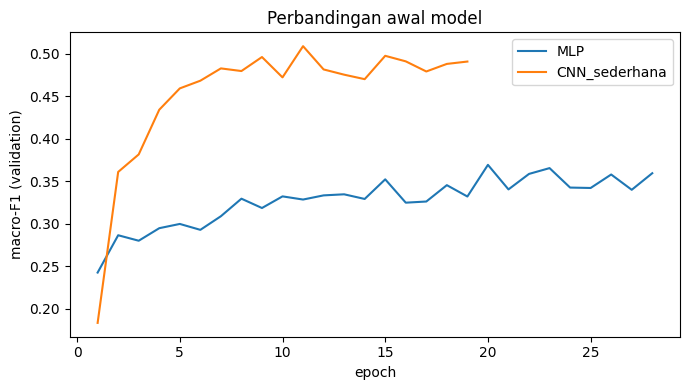

In [21]:
# ============================================================
# TAHAP 20 - Tabel perbandingan awal (validation)
# ============================================================
MODEL_AKTIF = [n for n in DAFTAR_MODEL if n in RESULTS]       # hanya model UTS (abaikan sisa hasil lama)
tabel_val = pd.DataFrame({n: RESULTS[n] for n in MODEL_AKTIF}).T
kolom = ["parameter", "epoch_terbaik", "epoch_dijalankan", "waktu_latih_detik",
         "train_loss", "train_acc", "val_loss", "val_acc", "val_f1"]
tabel_val = tabel_val[kolom].copy()
tabel_val["parameter"] = tabel_val["parameter"].astype(int)
for k in ("train_loss", "train_acc", "val_loss", "val_acc", "val_f1"):
    tabel_val[k] = tabel_val[k].astype(float).round(4)
display(tabel_val)
tabel_val.to_csv(LOG_DIR / "perbandingan_awal_validation.csv")

# Kurva macro-F1 validation per epoch
plt.figure(figsize=(7, 4))
for nama in MODEL_AKTIF:
    lg = pd.read_csv(LOG_DIR / f"{nama}_log.csv")
    plt.plot(lg["epoch"], lg["val_f1"], label=nama)
plt.xlabel("epoch"); plt.ylabel("macro-F1 (validation)"); plt.title("Perbandingan awal model")
plt.legend(); plt.tight_layout()
plt.savefig(FIG_DIR / "20_val_f1_per_epoch.png", dpi=150); plt.show()

## Tahap 21 — Evaluasi pada test set · Anggota 4 & 5

Mulai di sini **test set dipakai untuk pertama dan satu-satunya kali**. Setiap model dimuat dari bobot terbaik yang disimpan saat pelatihan (dipilih berdasarkan validation), lalu dievaluasi sekali. Metrik utama:
- **Akurasi** — proporsi prediksi benar;
- **Macro-F1** — rata-rata F1 semua kelas dengan bobot sama, sehingga kelas kecil seperti *disgust* tetap diperhitungkan;
- **Weighted-F1** — rata-rata F1 yang dibobot jumlah sampel per kelas;
- **Loss** — cross-entropy pada test.

In [22]:
# ============================================================
# TAHAP 21a - Evaluasi semua model pada test set (sekali)
# ============================================================
criterion_eval = nn.CrossEntropyLoss()
TEST_RES = {}

for nama in MODEL_AKTIF:
    model = MODEL_BUILDERS[nama]().to(DEVICE)
    model.load_state_dict(torch.load(MODEL_DIR / f"{nama}.pt", map_location=DEVICE))   # bobot terbaik (pilihan validation)
    r = evaluasi(model, test_loader, criterion_eval, return_probs=True)
    r["f1_weighted"] = f1_score(r["y_true"], r["y_pred"], average="weighted")
    TEST_RES[nama] = r

tabel_test = pd.DataFrame({
    nama: {
        "parameter": RESULTS[nama]["parameter"],
        "epoch terbaik": RESULTS[nama]["epoch_terbaik"],
        "waktu latih (detik)": RESULTS[nama]["waktu_latih_detik"],
        "val macro-F1": RESULTS[nama]["val_f1"],
        "test loss": r["loss"], "test akurasi": r["acc"],
        "test macro-F1": r["f1"], "test weighted-F1": r["f1_weighted"],
    } for nama, r in TEST_RES.items()
}).T
for k in ("val macro-F1", "test loss", "test akurasi", "test macro-F1", "test weighted-F1"):
    tabel_test[k] = tabel_test[k].astype(float).round(4)
tabel_test["parameter"] = tabel_test["parameter"].astype(int)
display(tabel_test)
tabel_test.to_csv(LOG_DIR / "hasil_test.csv")

# Model terbaik dipilih berdasarkan macro-F1 VALIDATION (test tidak dipakai untuk memilih model)
MODEL_TERBAIK = tabel_test["val macro-F1"].astype(float).idxmax()
print("Model terbaik (macro-F1 validation):", MODEL_TERBAIK)

,parameter,epoch terbaik,waktu latih (detik),val macro-F1,test loss,test akurasi,test macro-F1,test weighted-F1
MLP,1313287,20.0,47.2,0.3693,1.5650,0.4207,0.3740,0.4131
CNN_sederhana,1468135,11.0,122.8,0.5088,1.8507,0.5529,0.5211,0.5529


Model terbaik (macro-F1 validation): CNN_sederhana


## Tahap 22 — Grafik perbandingan akurasi dan loss

Kurva train vs validation memperlihatkan apakah model **overfitting** (loss validation naik atau akurasi validation menurun sementara train terus membaik) atau **underfitting**.

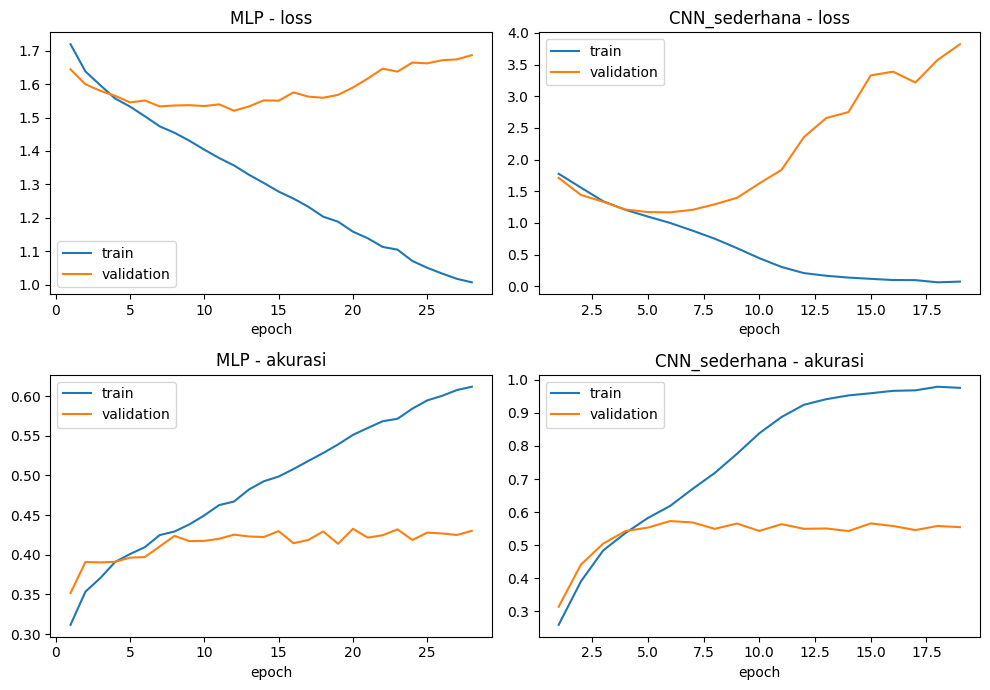

Catatan: pada MLP, akurasi/loss train dihitung saat dropout aktif.


In [23]:
# ============================================================
# TAHAP 22a - Kurva loss dan akurasi per model (train vs validation)
# ============================================================
nama_model = MODEL_AKTIF
fig, axes = plt.subplots(2, len(nama_model), figsize=(5 * len(nama_model), 7), squeeze=False)
for j, nama in enumerate(nama_model):
    lg = pd.read_csv(LOG_DIR / f"{nama}_log.csv")
    axes[0, j].plot(lg["epoch"], lg["train_loss"], label="train")
    axes[0, j].plot(lg["epoch"], lg["val_loss"], label="validation")
    axes[0, j].set_title(f"{nama} - loss"); axes[0, j].set_xlabel("epoch"); axes[0, j].legend()
    axes[1, j].plot(lg["epoch"], lg["train_acc"], label="train")
    axes[1, j].plot(lg["epoch"], lg["val_acc"], label="validation")
    axes[1, j].set_title(f"{nama} - akurasi"); axes[1, j].set_xlabel("epoch"); axes[1, j].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "22a_kurva_loss_akurasi.png", dpi=150); plt.show()
print("Catatan: pada MLP, akurasi/loss train dihitung saat dropout aktif.")

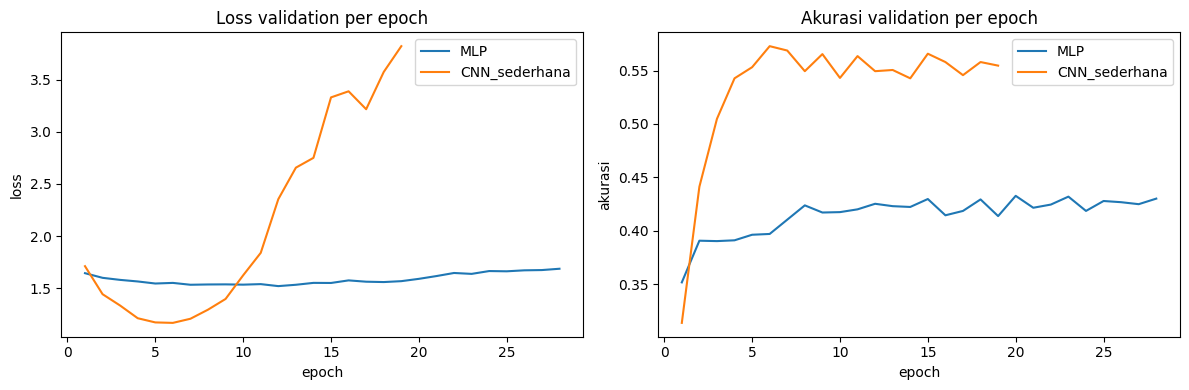

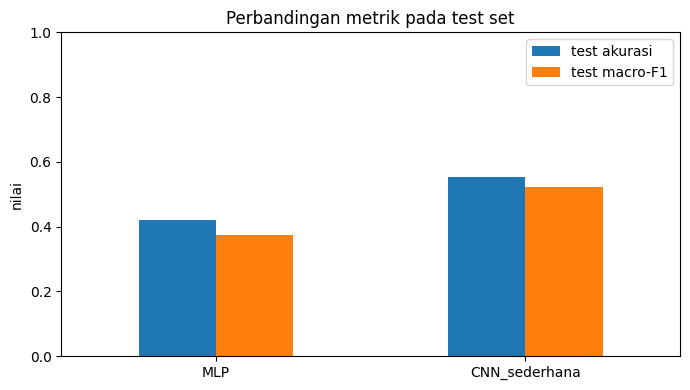

In [24]:
# ============================================================
# TAHAP 22b - Perbandingan MLP vs CNN: loss dan akurasi validation dalam satu grafik
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for nama in nama_model:
    lg = pd.read_csv(LOG_DIR / f"{nama}_log.csv")
    axes[0].plot(lg["epoch"], lg["val_loss"], label=nama)
    axes[1].plot(lg["epoch"], lg["val_acc"], label=nama)
axes[0].set_title("Loss validation per epoch"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss")
axes[1].set_title("Akurasi validation per epoch"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("akurasi")
axes[0].legend(); axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "22b_perbandingan_val.png", dpi=150); plt.show()

# Perbandingan metrik test (akurasi dan macro-F1)
tabel_test[["test akurasi", "test macro-F1"]].astype(float).plot(kind="bar", figsize=(7, 4))
plt.title("Perbandingan metrik pada test set"); plt.ylabel("nilai"); plt.xticks(rotation=0)
plt.ylim(0, 1); plt.tight_layout()
plt.savefig(FIG_DIR / "22c_metrik_test.png", dpi=150); plt.show()

## Tahap 23 — Classification report

Precision, recall, dan F1 per kelas memperlihatkan kelas mana yang sulit dikenali. Akurasi total bisa menutupi kelas yang buruk, terutama pada data tidak seimbang.

Classification report - MLP
              precision    recall  f1-score   support

       angry      0.321     0.221     0.262       958
     disgust      0.375     0.162     0.226       111
        fear      0.321     0.213     0.256      1024
       happy      0.545     0.635     0.586      1774
     neutral      0.381     0.492     0.430      1233
         sad      0.306     0.402     0.348      1247
    surprise      0.683     0.407     0.510       831

    accuracy                          0.421      7178
   macro avg      0.419     0.362     0.374      7178
weighted avg      0.427     0.421     0.413      7178

Classification report - CNN_sederhana
              precision    recall  f1-score   support

       angry      0.422     0.533     0.471       958
     disgust      0.458     0.396     0.425       111
        fear      0.405     0.370     0.387      1024
       happy      0.777     0.793     0.785      1774
     neutral      0.491     0.502     0.496      1233
         sad

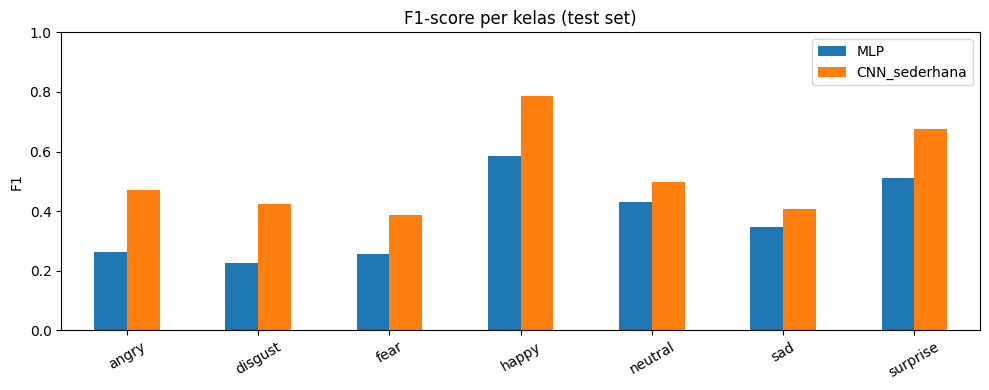

In [25]:
# ============================================================
# TAHAP 23 - Classification report per model (test set)
# ============================================================
REPORTS = {}
for nama, r in TEST_RES.items():
    print("=" * 66)
    print(f"Classification report - {nama}")
    print("=" * 66)
    print(classification_report(r["y_true"], r["y_pred"], target_names=CLASS_NAMES, digits=3, zero_division=0))
    rep = classification_report(r["y_true"], r["y_pred"], target_names=CLASS_NAMES,
                                output_dict=True, zero_division=0)
    REPORTS[nama] = pd.DataFrame(rep).T
    REPORTS[nama].to_csv(LOG_DIR / f"classification_report_{nama}.csv")

# F1 per kelas untuk semua model dalam satu grafik
f1_kelas = pd.DataFrame({nama: REPORTS[nama].loc[CLASS_NAMES, "f1-score"] for nama in REPORTS})
f1_kelas.plot(kind="bar", figsize=(10, 4))
plt.title("F1-score per kelas (test set)"); plt.ylabel("F1"); plt.xticks(rotation=30); plt.ylim(0, 1)
plt.tight_layout()
plt.savefig(FIG_DIR / "23_f1_per_kelas.png", dpi=150); plt.show()

## Tahap 24 — Confusion matrix

Baris = kelas sebenarnya, kolom = kelas prediksi. Matriks **jumlah** (atas) menunjukkan skala kesalahan, sedangkan matriks **ternormalisasi per baris** (bawah) menunjukkan *recall* tiap kelas sehingga kelas kecil tetap terbaca.

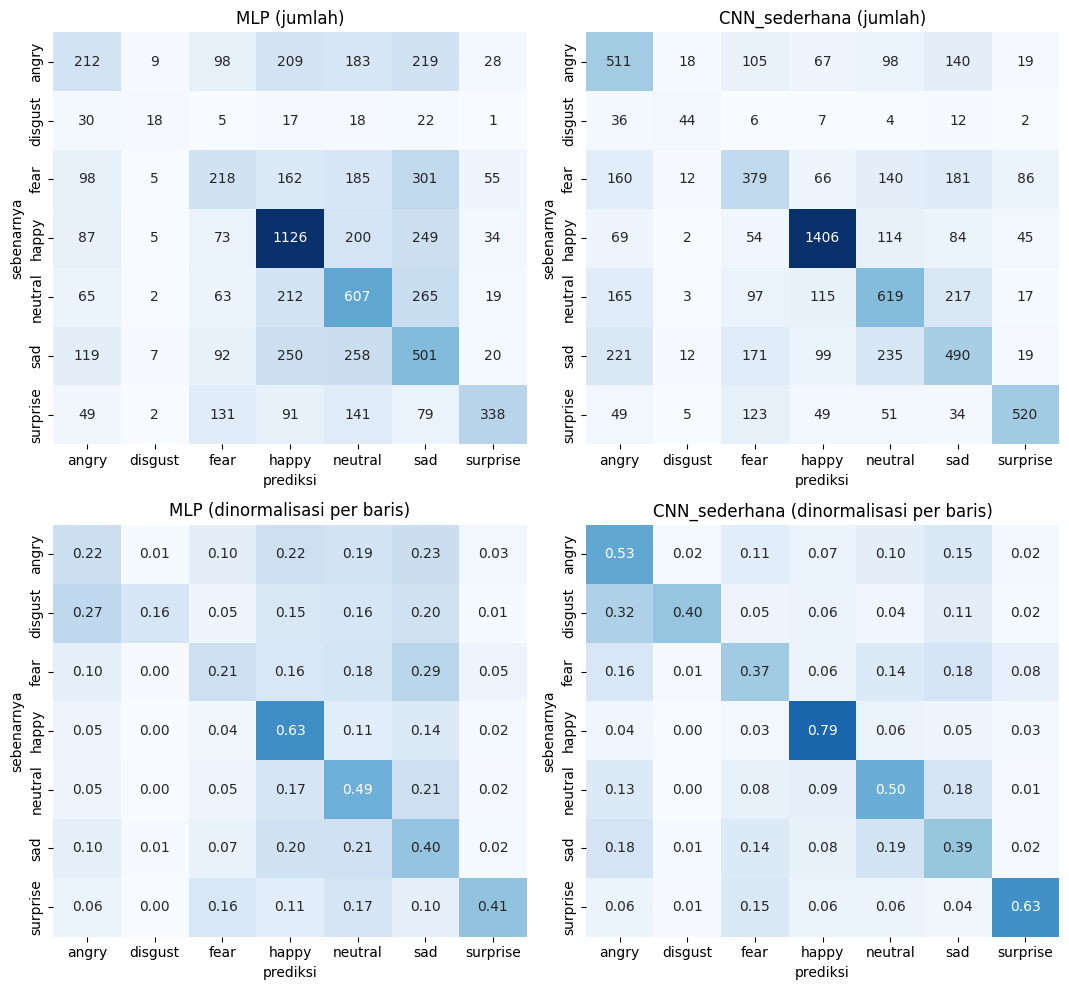

In [26]:
# ============================================================
# TAHAP 24 - Confusion matrix (jumlah dan ternormalisasi)
# ============================================================
fig, axes = plt.subplots(2, len(TEST_RES), figsize=(5.4 * len(TEST_RES), 10), squeeze=False)
for j, (nama, r) in enumerate(TEST_RES.items()):
    cm = confusion_matrix(r["y_true"], r["y_pred"], labels=range(NUM_CLASSES))
    cm_norm = confusion_matrix(r["y_true"], r["y_pred"], labels=range(NUM_CLASSES), normalize="true")
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0, j],
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    axes[0, j].set_title(f"{nama} (jumlah)")
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=axes[1, j],
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, vmin=0, vmax=1)
    axes[1, j].set_title(f"{nama} (dinormalisasi per baris)")
    for ax in (axes[0, j], axes[1, j]):
        ax.set_xlabel("prediksi"); ax.set_ylabel("sebenarnya")
plt.tight_layout()
plt.savefig(FIG_DIR / "24_confusion_matrix.png", dpi=150); plt.show()

## Tahap 25 — Analisis kesalahan dan contoh prediksi

Bagian ini menjawab pertanyaan "model salah di mana dan mengapa", untuk bahan **Pembahasan** laporan. Pasangan kelas yang paling sering tertukar dan contoh gambar yang salah diprediksi ditampilkan untuk model terbaik.

In [27]:
# ============================================================
# TAHAP 25a - Pasangan kelas yang paling sering tertukar (model terbaik)
# ============================================================
r = TEST_RES[MODEL_TERBAIK]
cm = confusion_matrix(r["y_true"], r["y_pred"], labels=range(NUM_CLASSES))
pasangan = []
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if i != j and cm[i, j] > 0:
            pasangan.append((CLASS_NAMES[i], CLASS_NAMES[j], int(cm[i, j]), cm[i, j] / cm[i].sum()))
pasangan.sort(key=lambda t: -t[2])

tabel_pasangan = pd.DataFrame(pasangan[:8], columns=["kelas sebenarnya", "diprediksi sebagai", "jumlah", "% dari kelasnya"])
tabel_pasangan["% dari kelasnya"] = (100 * tabel_pasangan["% dari kelasnya"]).round(1)
print(f"Kesalahan terbanyak - model {MODEL_TERBAIK}:")
display(tabel_pasangan)

Kesalahan terbanyak - model CNN_sederhana:


,kelas sebenarnya,diprediksi sebagai,jumlah,% dari kelasnya
0,sad,neutral,235,18.8
1,sad,angry,221,17.7
2,neutral,sad,217,17.6
3,fear,sad,181,17.7
4,sad,fear,171,13.7
5,neutral,angry,165,13.4
6,fear,angry,160,15.6
7,angry,sad,140,14.6


CNN_sederhana: 3209 dari 7178 citra test salah diprediksi


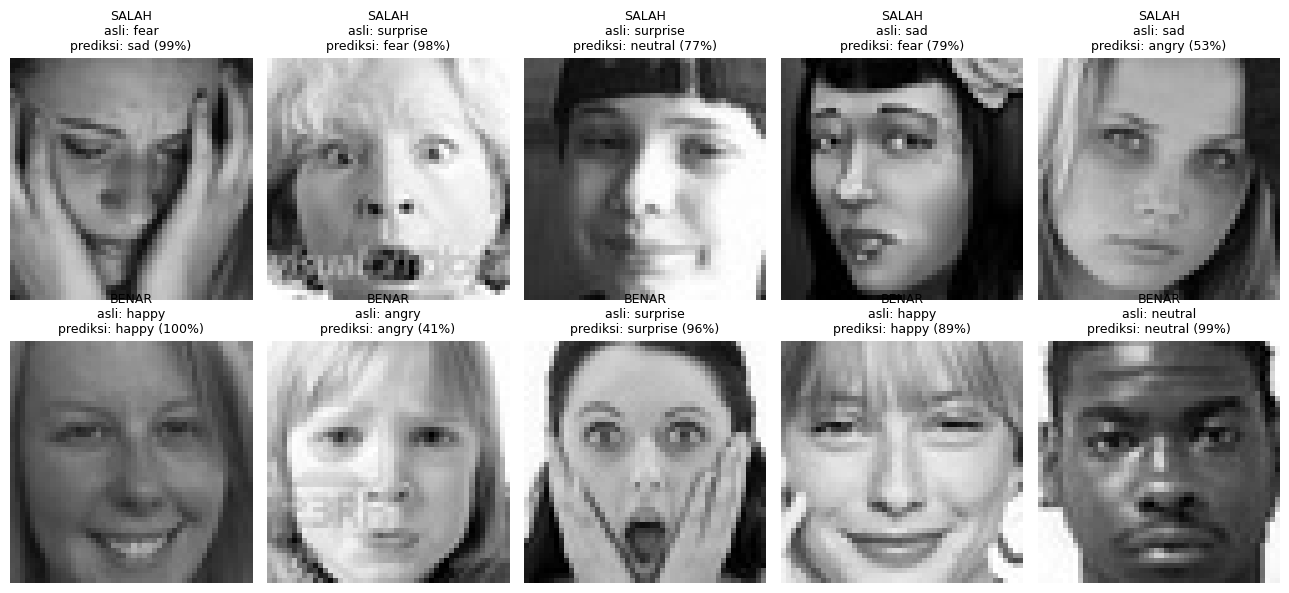

In [28]:
# ============================================================
# TAHAP 25b - Contoh prediksi salah dan benar (model terbaik)
# ============================================================
rng = np.random.RandomState(SEED)
salah = np.where(r["y_true"] != r["y_pred"])[0]
benar = np.where(r["y_true"] == r["y_pred"])[0]
print(f"{MODEL_TERBAIK}: {len(salah)} dari {len(r['y_true'])} citra test salah diprediksi")

pilih_salah = rng.choice(salah, size=min(5, len(salah)), replace=False)
pilih_benar = rng.choice(benar, size=min(5, len(benar)), replace=False)

fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for baris, (judul, pilihan) in enumerate([("SALAH", pilih_salah), ("BENAR", pilih_benar)]):
    for ax, k in zip(axes[baris], pilihan):
        ax.imshow(X_te[k], cmap="gray", vmin=0, vmax=255)
        yakin = r["probs"][k, r["y_pred"][k]]
        ax.set_title(f"{judul}\nasli: {CLASS_NAMES[r['y_true'][k]]}\nprediksi: {CLASS_NAMES[r['y_pred'][k]]} ({yakin:.0%})", fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "25_contoh_prediksi.png", dpi=150); plt.show()

## Tahap 26 — Keterbatasan model dan ringkasan otomatis untuk laporan

Sel berikut menghitung fakta-fakta dari hasil percobaan (ketidakseimbangan kelas, kelas terlemah, selisih train–validation, penanganan kebocoran) dan mencetaknya sebagai **catatan untuk bagian Pembahasan**. Kesimpulannya tetap harus dibaca dan ditulis ulang oleh anggota dengan bahasa sendiri.

In [29]:
# ============================================================
# TAHAP 26 - Ringkasan hasil dan catatan keterbatasan
# ============================================================
rasio = ringkasan_split.loc[CLASS_NAMES, "train"].max() / ringkasan_split.loc[CLASS_NAMES, "train"].min()
kelas_terbanyak = ringkasan_split.loc[CLASS_NAMES, "train"].idxmax()
kelas_tersedikit = ringkasan_split.loc[CLASS_NAMES, "train"].idxmin()

f1_terbaik = REPORTS[MODEL_TERBAIK].loc[CLASS_NAMES, "f1-score"]
kelas_terlemah, kelas_terkuat = f1_terbaik.idxmin(), f1_terbaik.idxmax()
res_terbaik = RESULTS[MODEL_TERBAIK]
gap_acc = res_terbaik["train_acc"] - res_terbaik["val_acc"]

print("RINGKASAN HASIL (test set)")
print("-" * 60)
display(tabel_test[["test akurasi", "test macro-F1", "test weighted-F1", "test loss"]])
print(f"Model terbaik berdasarkan macro-F1 validation : {MODEL_TERBAIK}")

print("\nCATATAN KETERBATASAN UNTUK PEMBAHASAN")
print("-" * 60)
print(f"1. Ketidakseimbangan kelas: '{kelas_terbanyak}' vs '{kelas_tersedikit}' berbanding {rasio:.1f} : 1 pada data latih.")
print(f"   Kelas terlemah (F1 {f1_terbaik[kelas_terlemah]:.3f}): '{kelas_terlemah}'; terkuat (F1 {f1_terbaik[kelas_terkuat]:.3f}): '{kelas_terkuat}'.")
print(f"2. Selisih akurasi train - validation pada {MODEL_TERBAIK} di epoch terbaik: {gap_acc:+.3f}")
print("   (nilai besar menandakan overfitting).")
if HAPUS_BOCOR:
    print(f"3. Kebocoran data ditangani: {int(mask_bocor.sum())} citra train yang identik dengan test dikeluarkan dari data latih.")
else:
    print(f"3. Kebocoran data TIDAK ditangani: {int(mask_bocor.sum())} citra train identik dengan test, sehingga akurasi test mungkin terlalu optimis.")
print("4. Hanya satu run per model dengan seed tetap; belum ada pengulangan multi-seed, jadi selisih kecil antar model belum tentu bermakna.")
print("5. Hyperparameter belum dituning secara sistematis (itu bagian UAS); arsitektur dan LR dipilih sebagai baseline.")
print("6. Label FER-2013 berasal dari anotasi citra web dan dikenal memuat label yang berisik/ambigu, sehingga ada batas atas akurasi yang realistis.")
print("7. Citra hanya 48x48 grayscale: detail halus (misalnya kerutan) terbatas.")

RINGKASAN HASIL (test set)
------------------------------------------------------------


,test akurasi,test macro-F1,test weighted-F1,test loss
MLP,0.4207,0.3740,0.4131,1.5650
CNN_sederhana,0.5529,0.5211,0.5529,1.8507


Model terbaik berdasarkan macro-F1 validation : CNN_sederhana

CATATAN KETERBATASAN UNTUK PEMBAHASAN
------------------------------------------------------------
1. Ketidakseimbangan kelas: 'happy' vs 'disgust' berbanding 20.1 : 1 pada data latih.
   Kelas terlemah (F1 0.387): 'fear'; terkuat (F1 0.785): 'happy'.
2. Selisih akurasi train - validation pada CNN_sederhana di epoch terbaik: +0.324
   (nilai besar menandakan overfitting).
3. Kebocoran data ditangani: 703 citra train yang identik dengan test dikeluarkan dari data latih.
4. Hanya satu run per model dengan seed tetap; belum ada pengulangan multi-seed, jadi selisih kecil antar model belum tentu bermakna.
5. Hyperparameter belum dituning secara sistematis (itu bagian UAS); arsitektur dan LR dipilih sebagai baseline.
6. Label FER-2013 berasal dari anotasi citra web dan dikenal memuat label yang berisik/ambigu, sehingga ada batas atas akurasi yang realistis.
7. Citra hanya 48x48 grayscale: detail halus (misalnya kerutan) terbatas.

## Tahap 27 — Menyimpan dan mengunduh hasil

Folder `/content` pada Colab **hilang saat sesi berakhir**. Sel 27a mencatat versi library untuk `requirements.txt`; sel 27b membuat file ZIP berisi bobot model, log pelatihan, grafik, tabel hasil, dan daftar versi library, lalu mengunduhnya ke laptop. Opsional: salin juga ke Google Drive dengan `SIMPAN_KE_DRIVE = True`.

In [30]:
# ============================================================
# TAHAP 27a - Mencatat versi library (untuk requirements.txt)
# ============================================================
from importlib.metadata import version

paket = ["torch", "torchvision", "numpy", "pandas", "matplotlib", "seaborn", "scikit-learn", "Pillow"]
baris = [f"{p}=={version(p).split('+')[0]}" for p in paket]      # buang akhiran build (mis. +cu130)
(OUT_DIR / "requirements_versi_colab.txt").write_text("\n".join(baris) + "\n")
print("\n".join(baris))

torch==2.11.0
torchvision==0.26.0
numpy==2.1.3
pandas==2.2.3
matplotlib==3.10.0
seaborn==0.13.2
scikit-learn==1.6.1
Pillow==11.3.0


In [31]:
# ============================================================
# TAHAP 27b - Zip semua keluaran dan unduh
# ============================================================
SIMPAN_KE_DRIVE = False        # ganti True untuk menyalin ke Google Drive
FOLDER_DRIVE = "/content/drive/MyDrive/fer2013_uts_hasil"

zip_path = shutil.make_archive("/content/hasil_uts", "zip", OUT_DIR)
print("ZIP dibuat:", zip_path)
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file():
        print(f"  {str(p.relative_to(OUT_DIR)):55s} {p.stat().st_size / 1024:9.1f} KB")

if SIMPAN_KE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    shutil.copytree(OUT_DIR, FOLDER_DRIVE, dirs_exist_ok=True)
    print("Disalin ke Drive:", FOLDER_DRIVE)

from google.colab import files
files.download(zip_path)       # mengunduh ZIP ke laptop

ZIP dibuat: /content/hasil_uts.zip
  figures/20_val_f1_per_epoch.png                              55.8 KB
  figures/22a_kurva_loss_akurasi.png                          136.2 KB
  figures/22b_perbandingan_val.png                             73.5 KB
  figures/22c_metrik_test.png                                  27.8 KB
  figures/23_f1_per_kelas.png                                  38.6 KB
  figures/24_confusion_matrix.png                             251.2 KB
  figures/25_contoh_prediksi.png                              113.6 KB
  logs/CNN_sederhana_log.csv                                    2.3 KB
  logs/MLP_log.csv                                              3.4 KB
  logs/classification_report_CNN_sederhana.csv                  0.7 KB
  logs/classification_report_MLP.csv                            0.7 KB
  logs/hasil_ringkas.json                                       0.6 KB
  logs/hasil_test.csv                                           0.2 KB
  logs/perbandingan_awal_validation.csv   

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Checklist hasil kerja

**Anggota 3 (MLP)** — kode model MLP (Tahap 18), penjelasan input/output/forward/loss/optimizer (markdown Tahap 18), log pelatihan `logs/MLP_log.csv`, bobot `models/MLP.pt`, hasil baseline pertama (Tahap 20). Kemudian, kode CNN (Tahap 19), log `logs/CNN_sederhana_log.csv`, waktu pelatihan dan parameter pada `perbandingan_awal_validation.csv`, tabel perbandingan awal MLP vs CNN (Tahap 20).

**Anggota 4 & 5 (Evaluasi & dokumentasi)** — evaluasi test (Tahap 21), grafik akurasi/loss (Tahap 22), classification report (Tahap 23), confusion matrix (Tahap 24), analisis kesalahan (Tahap 25), catatan keterbatasan (Tahap 26). Materi tinjauan pustaka, metode evaluasi, hasil, dan pembahasan disusun **setelah angka hasil pelatihan keluar**.

**Pemetaan ke laporan UTS:** Dataset & preprocessing ← Tahap 4–9, 15–16; Metodologi ← markdown Tahap 18–19 dan Tahap 13a (hyperparameter); Eksperimen & hasil ← Tahap 20–24; Pembahasan ← Tahap 25–26; Lampiran ← tabel pembagian tugas dan tautan repositori.